# Pipeline do *framework* — passo a passo

Percurso completo da cadeia implementada, com um caso **simplificado**, usando as funções
dos módulos de `sed_meta`. O objetivo é verificar que a implementação gera o que precisa
gerar, na forma em que precisa gerar.

**Roteiro**

1. Declarar o espaço de parâmetros
2. Gerar o plano por **Monte Carlo**, **LHS** e **Sobol**, e medir o preenchimento do espaço
3. Expandir o plano escolhido em **replicações**
4. Inspecionar o resultado do DoE (`.describe()` e o próprio *DataFrame*)
5. **Fingir que a simulação rodou** — gerar KPIs sintéticos
6. Agregar por ponto e calcular o teto de ruído
7. Pré-processar (partição, codificação das entradas, transformação do alvo)
8. Treinar um **Random Forest** e avaliar contra o piso e o teto

> As Fases 4 (avaliação) e 5 (explicabilidade) ainda não estão implementadas; o notebook
> termina no modelo treinado.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> src/

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

SEED = 42
print("pronto")

pronto


---
## 1. Espaço de parâmetros

Caso simplificado inspirado no cenário de linha sequencial. Quatro fatores, cobrindo
quatro das cinco naturezas que o módulo aceita — contínuo, inteiro, categórico nominal e
binário.

O espaço é declarado **antes de qualquer simulação**: os limites vêm da definição do
problema, não dos dados. Essa é a propriedade de que o pré-processamento depende na
etapa 7.

In [2]:
from sed_meta.doe.parameter_space import ParameterSpec, generate_design

specs = [
    ParameterSpec("taxa_chegada",   "float",       low=5.0, high=20.0),
    ParameterSpec("num_operadores", "integer",     low=1,   high=4),
    ParameterSpec("regra_despacho", "categorical", levels=["FIFO", "SPT", "EDD"]),
    ParameterSpec("turno_extra",    "binary",      ordered=True),
]

pd.DataFrame([
    {"fator": s.name, "tipo": s.type,
     "domínio": (f"[{s.low}, {s.high}]" if s.low is not None
                 else (str(s.levels) if s.levels else "{0, 1}"))}
    for s in specs
])

,fator,tipo,domínio
0,taxa_chegada,float,"[5.0, 20.0]"
1,num_operadores,integer,"[1, 4]"
2,regra_despacho,categorical,"['FIFO', 'SPT', 'EDD']"
3,turno_extra,binary,"{0, 1}"


---
## 2. Métodos de amostragem e preenchimento do espaço

Os três métodos previstos na metodologia. O **Monte Carlo é o *baseline*** contra o qual
os outros dois são comparados.

O Sobol não aceita fator categórico (não há definição nativa de sequência de baixa
discrepância sobre rótulos), então a **comparação quantitativa** usa o subespaço numérico
— que é também onde as métricas de preenchimento estão definidas.

> **Nota sobre o Sobol:** as propriedades de balanceamento valem para $n$ potência de 2.
> Usamos $n = 64$.

In [3]:
specs_num = [s for s in specs if s.type in ("float", "integer")]
N = 64                      # potência de 2, para não desperdiçar o Sobol

designs = {
    "monte_carlo": generate_design(specs_num, n_points=N, seed=SEED, method="monte_carlo"),
    "lhs":         generate_design(specs_num, n_points=N, seed=SEED, method="lhs"),
    "sobol":       generate_design(specs_num, n_points=N, seed=SEED, method="sobol"),
}

# os três precisam ser genuinamente distintos
print("monte_carlo == lhs ?",
      np.allclose(designs["monte_carlo"]["taxa_chegada"], designs["lhs"]["taxa_chegada"]))
print("lhs         == sobol ?",
      np.allclose(designs["lhs"]["taxa_chegada"], designs["sobol"]["taxa_chegada"]))

designs["monte_carlo"].head()

monte_carlo == lhs ? False
lhs         == sobol ? False


,taxa_chegada,num_operadores
0,16.609341,2
1,17.878969,3
2,6.412660,4
3,16.417096,4
4,6.921704,2


### 2.1 Métricas de preenchimento

Todas calculadas sobre o espaço **normalizado para $[0,1]^d$**, para que fatores de
unidades diferentes pesem igual.

| Métrica | O que mede | Direção |
|---|---|---|
| Distância mínima entre pontos | O par mais próximo — detecta aglomeração | **maior é melhor** |
| Distância média ao vizinho mais próximo | Espaçamento típico | **maior é melhor** |
| Desvio da distância ao vizinho | Regularidade do espaçamento | menor é melhor |
| Distância média entre todos os pares | Espalhamento global | maior é melhor |
| Cobertura dos vértices | Distância média de cada vértice do hipercubo ao ponto mais próximo — detecta vazios nos **cantos** | **menor é melhor** |
| Discrepância $L^2$ estrela | Desvio da distribuição uniforme ideal (medida clássica de QMC) | menor é melhor |
| Dispersão dos espaçamentos marginais | Uniformidade **por fator** — é o que o LHS garante por construção | menor é melhor |

In [4]:
from itertools import product
from scipy.spatial.distance import pdist, squareform
from scipy.stats import qmc


def para_cubo_unitario(df, specs):
    # normaliza pelos limites DECLARADOS no spec, não pelos observados
    return np.column_stack([
        (df[s.name].to_numpy(float) - s.low) / (s.high - s.low) for s in specs
    ])


def metricas_preenchimento(df, specs):
    U = para_cubo_unitario(df, specs)
    n, d = U.shape

    D = squareform(pdist(U))
    np.fill_diagonal(D, np.inf)
    vizinho = D.min(axis=1)

    # distância de cada vértice do hipercubo ao ponto mais próximo do design
    vertices = np.array(list(product([0.0, 1.0], repeat=d)))
    dist_vertices = np.min(
        np.linalg.norm(vertices[:, None, :] - U[None, :, :], axis=2), axis=1
    )

    # uniformidade marginal: dispersão dos espaçamentos, por fator
    disp_marginal = np.mean([
        np.std(np.diff(np.sort(U[:, j]))) for j in range(d)
    ])

    return {
        "dist. mín. entre pontos":      D.min(),
        "dist. média ao vizinho":       vizinho.mean(),
        "desvio dist. ao vizinho":      vizinho.std(),
        "dist. média entre pares":      pdist(U).mean(),
        "cobertura dos vértices":       dist_vertices.mean(),
        "discrepância L2-estrela":      qmc.discrepancy(U, method="L2-star"),
        "disp. espaç. marginal":        disp_marginal,
    }


tabela = pd.DataFrame({m: metricas_preenchimento(d, specs_num)
                       for m, d in designs.items()})
tabela.round(5)

,monte_carlo,lhs,sobol
dist. mín. entre pontos,0.00181,0.00573,0.00578
dist. média ao vizinho,0.03365,0.04309,0.03675
desvio dist. ao vizinho,0.03221,0.02675,0.02134
dist. média entre pares,0.57628,0.60582,0.60786
cobertura dos vértices,0.07320,0.03818,0.03123
discrepância L2-estrela,0.06643,0.06881,0.06837
disp. espaç. marginal,0.04336,0.03856,0.03768


**Como ler.** Nas quatro primeiras linhas e na última, o LHS e o Sobol devem bater o
Monte Carlo: a amostragem aleatória aglomera pontos e deixa vazios, o que aparece como
distância mínima pequena e dispersão marginal alta. A linha de vértices mostra quem
cobre melhor os **cantos** do espaço — região que costuma ser a mais crítica num DoE e a
que a amostragem aleatória mais frequentemente deixa descoberta.

In [5]:
ordem_maior_melhor = ["dist. mín. entre pontos", "dist. média ao vizinho",
                      "dist. média entre pares"]

vencedor = {}
for metrica in tabela.index:
    linha = tabela.loc[metrica]
    vencedor[metrica] = linha.idxmax() if metrica in ordem_maior_melhor else linha.idxmin()

pd.DataFrame({"melhor método": pd.Series(vencedor)})

,melhor método
dist. mín. entre pontos,sobol
dist. média ao vizinho,lhs
desvio dist. ao vizinho,sobol
dist. média entre pares,sobol
cobertura dos vértices,sobol
discrepância L2-estrela,monte_carlo
disp. espaç. marginal,sobol


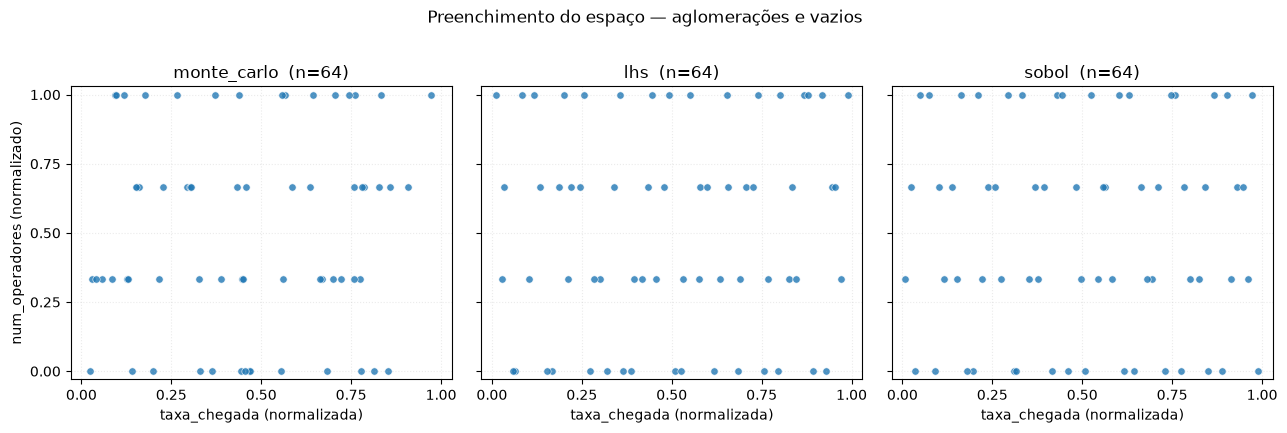

In [6]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for eixo, (nome, d) in zip(eixos, designs.items()):
    U = para_cubo_unitario(d, specs_num)
    eixo.scatter(U[:, 0], U[:, 1], s=28, alpha=0.8, edgecolor="white", linewidth=0.5)
    eixo.set_title(f"{nome}  (n={N})")
    eixo.set_xlabel("taxa_chegada (normalizada)")
    eixo.set_xlim(-0.03, 1.03); eixo.set_ylim(-0.03, 1.03)
    eixo.set_xticks(np.linspace(0, 1, 5)); eixo.set_yticks(np.linspace(0, 1, 5))
    eixo.grid(alpha=0.25, linestyle=":")
eixos[0].set_ylabel("num_operadores (normalizado)")
fig.suptitle("Preenchimento do espaço — aglomerações e vazios", y=1.02)
plt.tight_layout(); plt.show()

O eixo vertical é um fator **inteiro** de 4 níveis, então os pontos se alinham em quatro
faixas nos três métodos — comportamento correto, não artefato. A diferença entre os
métodos aparece no eixo horizontal (contínuo) e na forma como os pontos se distribuem
dentro de cada faixa.

---
## 3. Plano do estudo e replicações

Seguindo a metodologia, o **LHS é o método principal**. Daqui em diante o plano usa o
espaço completo (com o fator categórico).

Cada ponto é executado mais de uma vez porque o simulador é estocástico. A expansão
produz uma linha por execução, com semente derivada de forma determinística do ponto e
do índice da replicação.

In [7]:
from sed_meta.doe.replication import (
    ReplicationPolicy, build_execution_plan,
    aggregate_replications, compute_noise_ceiling,
)

N_PONTOS, N_REP = 40, 5

design = generate_design(specs, n_points=N_PONTOS, seed=SEED, method="lhs")
plano = build_execution_plan(design, ReplicationPolicy(n_replications=N_REP, seed_base=0))

print(f"{N_PONTOS} pontos x {N_REP} replicações = {len(plano)} execuções")
print(f"sementes únicas: {plano['seed'].nunique()}")
plano.head(12)

40 pontos x 5 replicações = 200 execuções
sementes únicas: 200


,point_id,replication_id,seed,taxa_chegada,num_operadores,regra_despacho,turno_extra
0,0,0,0,8.122185,1,SPT,0
1,0,1,1,8.122185,1,SPT,0
2,0,2,2,8.122185,1,SPT,0
3,0,3,3,8.122185,1,SPT,0
4,0,4,4,8.122185,1,SPT,0
5,1,0,5,16.469037,3,FIFO,0
6,1,1,6,16.469037,3,FIFO,0
7,1,2,7,16.469037,3,FIFO,0
8,1,3,8,16.469037,3,FIFO,0
9,1,4,9,16.469037,3,FIFO,0


As cinco primeiras linhas repetem os parâmetros do ponto 0 e variam só a semente — é
exatamente isso que caracteriza a replicação. Os `dtypes` sobrevivem à expansão:

In [8]:
pd.DataFrame({"dtype": plano.dtypes.astype(str)})

,dtype
point_id,int64
replication_id,int64
seed,int64
taxa_chegada,float64
num_operadores,int64
regra_despacho,category
turno_extra,int64


---
## 4. O resultado do DoE

O plano completo e sua descrição estatística.

In [9]:
design.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
taxa_chegada,40.0,NaN,NaN,NaN,12.487003,4.375126,5.290234,8.791379,12.492108,16.236843,19.730463
num_operadores,40.0,NaN,NaN,NaN,2.5,1.132277,1.0,1.75,2.5,3.25,4.0
regra_despacho,40,3,SPT,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
turno_extra,40.0,NaN,NaN,NaN,0.5,0.50637,0.0,0.0,0.5,1.0,1.0


In [10]:
design

,taxa_chegada,num_operadores,regra_despacho,turno_extra
0,8.122185,1,SPT,0
1,16.469037,3,FIFO,0
2,13.310477,3,EDD,0
3,6.366449,3,EDD,0
4,7.159283,1,EDD,1
5,6.707969,3,SPT,1
6,10.875651,4,FIFO,0
7,12.749118,3,SPT,1
8,14.135680,1,EDD,1
9,15.042032,2,SPT,1


---
## 5. Fingindo que a simulação rodou

Substitui-se aqui a campanha no ProModel por uma resposta sintética. Usa-se uma forma
funcional de fila — tempo de atravessamento crescendo de modo não linear com a utilização
e explodindo perto da saturação — com ruído **multiplicativo lognormal**, que reproduz
duas características reais do SED estocástico:

- assimetria à direita (motiva a transformação logarítmica do alvo na etapa 7);
- **heterocedasticidade** — a dispersão entre replicações cresce com a utilização, e é
  isso que dá sentido ao peso amostral calculado na etapa 6.

Na campanha real, esta célula é substituída pelo preenchimento da planilha pelo ProModel;
o restante do notebook não muda.

In [11]:
rng = np.random.default_rng(SEED)

capacidade = plano["num_operadores"].to_numpy(float) * (
    1.0 + 0.25 * plano["turno_extra"].to_numpy(float)
)
# a regra de despacho desloca levemente a capacidade efetiva
efeito_regra = plano["regra_despacho"].map({"FIFO": 1.00, "SPT": 1.12, "EDD": 1.05})
utilizacao = np.clip(
    plano["taxa_chegada"].to_numpy(float)
    / (capacidade * efeito_regra.to_numpy(float) * 7.0),
    0.05, 0.97,
)

resultados = plano.copy()
resultados["lead_time"] = (
    4.0 * utilizacao / (1.0 - utilizacao) * rng.lognormal(0.0, 0.18, len(plano))
)
resultados["throughput"] = 60.0 * utilizacao * capacidade + rng.normal(0.0, 2.0, len(plano))

KPIS = ["lead_time", "throughput"]
resultados[["point_id", "replication_id", "taxa_chegada", "num_operadores",
            "regra_despacho", "lead_time", "throughput"]].head(10)

,point_id,replication_id,taxa_chegada,num_operadores,regra_despacho,lead_time,throughput
0,0,0,8.122185,1,SPT,136.625298,58.875149
1,0,1,8.122185,1,SPT,107.253577,61.014964
2,0,2,8.122185,1,SPT,148.038780,58.381170
3,0,3,8.122185,1,SPT,153.192408,59.487878
4,0,4,8.122185,1,SPT,91.031602,54.099656
5,1,0,16.469037,3,FIFO,11.501179,141.065735
6,1,1,16.469037,3,FIFO,14.877547,139.476712
7,1,2,16.469037,3,FIFO,13.734600,138.725546
8,1,3,16.469037,3,FIFO,14.495201,139.406867
9,1,4,16.469037,3,FIFO,12.469603,140.494925


A heterocedasticidade da resposta sintética, que é o ponto da simulação:

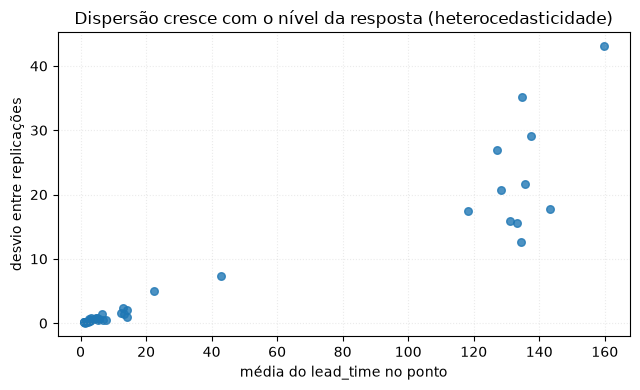

In [12]:
por_ponto = resultados.groupby("point_id")["lead_time"].agg(["mean", "std"])
fig, eixo = plt.subplots(figsize=(6.5, 4))
eixo.scatter(por_ponto["mean"], por_ponto["std"], s=30, alpha=0.8)
eixo.set_xlabel("média do lead_time no ponto")
eixo.set_ylabel("desvio entre replicações")
eixo.set_title("Dispersão cresce com o nível da resposta (heterocedasticidade)")
eixo.grid(alpha=0.25, linestyle=":")
plt.tight_layout(); plt.show()

---
## 6. Agregação por ponto e teto de ruído

A agregação consolida as replicações de cada ponto em uma observação, guardando também
as grandezas que descrevem a confiabilidade dessa média.

O **teto de ruído** decompõe a variância total em variação entre pontos (sinal) e entre
replicações do mesmo ponto (ruído do simulador). Ele é o limite superior do $R^2$ que
qualquer metamodelo pode legitimamente atingir — e sem ele não há como saber se um $R^2$
de 0,93 é bom ou ruim.

In [13]:
param_cols = [s.name for s in specs]
dataset = aggregate_replications(resultados, param_cols=param_cols, kpi_cols=KPIS)

print(f"dataset agregado: {dataset.shape[0]} linhas (1 por ponto) x {dataset.shape[1]} colunas")
dataset.head()

dataset agregado: 40 linhas (1 por ponto) x 15 colunas


,point_id,taxa_chegada,num_operadores,regra_despacho,turno_extra,lead_time_mean,lead_time_std,lead_time_n,lead_time_sem,lead_time_sample_weight,throughput_mean,throughput_std,throughput_n,throughput_sem,throughput_sample_weight
0,0,8.122185,1,SPT,0,127.228333,26.947658,5,12.051359,0.001377,58.371763,2.585373,5,1.156214,0.149608
1,1,16.469037,3,FIFO,0,13.415626,1.411073,5,0.631051,0.502228,139.833957,0.934447,5,0.417897,1.145226
2,2,13.310477,3,EDD,0,6.879777,0.499249,5,0.223271,4.012042,108.180274,1.629998,5,0.728957,0.376380
3,3,6.366449,3,EDD,0,1.600722,0.227899,5,0.101920,19.253709,52.782145,1.664187,5,0.744247,0.361073
4,4,7.159283,1,EDD,1,14.109290,2.011977,5,0.899784,0.247032,58.123651,1.093893,5,0.489204,0.835700


In [14]:
teto = compute_noise_ceiling(resultados, KPIS)
for kpi, valor in teto.items():
    print(f"{kpi:12s} teto de ruído = {valor:.4f}")

lead_time    teto de ruído = 0.9503
throughput   teto de ruído = 0.9961


O peso amostral é o inverso da variância do ponto: pontos onde o simulador foi errático
pesam menos no ajuste. A amplitude entre o ponto mais estável e o mais ruidoso mostra
quanta informação a replicação produz:

In [15]:
peso = dataset["lead_time_sample_weight"]
print(f"peso mínimo : {peso.min():.4f}")
print(f"peso máximo : {peso.max():.4f}")
print(f"razão       : {peso.max() / peso.min():,.0f}x")

dataset[["point_id", "lead_time_mean", "lead_time_std", "lead_time_n",
         "lead_time_sem", "lead_time_sample_weight"]].head(8)

peso mínimo : 0.0005
peso máximo : 169.0541
razão       : 313,774x


,point_id,lead_time_mean,lead_time_std,lead_time_n,lead_time_sem,lead_time_sample_weight
0,0,127.228333,26.947658,5,12.051359,0.001377
1,1,13.415626,1.411073,5,0.631051,0.502228
2,2,6.879777,0.499249,5,0.223271,4.012042
3,3,1.600722,0.227899,5,0.101920,19.253709
4,4,14.109290,2.011977,5,0.899784,0.247032
5,5,1.245078,0.076911,5,0.034396,169.054135
6,6,2.689120,0.634000,5,0.283534,2.487833
7,7,3.093932,0.495794,5,0.221726,4.068156


---
## 7. Pré-processamento

A ordem é deliberada e importa: **partição primeiro, ajuste depois**.

- **Entradas (X):** codificadas a partir dos limites *declarados* no `ParameterSpec` —
  não dos observados. Ajustar em qualquer subconjunto das linhas dá o mesmo resultado.
- **Alvo (y):** a transformação é aprendida, e **só** da partição de treino. Ajustar
  antes de particionar contaminaria o treino com estatísticas do teste.

O `lead_time` usa `log_standard` (logaritmo antes da padronização) pela assimetria à
direita observada na etapa 5.

In [16]:
from sed_meta.preprocessing import PreprocessingPipeline, TargetTransformSpec

alvos = [
    TargetTransformSpec("lead_time",  method="log_standard"),
    TargetTransformSpec("throughput", method="standard"),
]

pipe = PreprocessingPipeline(specs, alvos)

train_df, test_df = pipe.split(dataset, test_size=0.25, seed=SEED)   # 1º: particionar
pipe.fit(train_df)                                                   # 2º: ajustar só no treino

X_train = pipe.transform_X(train_df)
X_test  = pipe.transform_X(test_df)
y_train = pipe.transform_y(train_df, "lead_time")
y_test  = pipe.transform_y(test_df,  "lead_time")

print(f"partição : {len(dataset)} pontos -> {len(train_df)} treino / {len(test_df)} teste")
print(f"X        : {X_train.shape} treino, {X_test.shape} teste")
print(f"colunas  : {pipe.get_feature_names()}")

partição : 40 pontos -> 30 treino / 10 teste
X        : (30, 6) treino, (10, 6) teste
colunas  : ['taxa_chegada', 'num_operadores', 'regra_despacho_FIFO', 'regra_despacho_SPT', 'regra_despacho_EDD', 'turno_extra']


Quatro fatores viraram seis colunas: o categórico de três níveis expandiu em três
indicadoras. Verificações das duas propriedades que o módulo promete:

In [17]:
# (a) entradas: ajustar em 1 linha == ajustar no treino inteiro
uma_linha = pipe.transform_X(train_df.iloc[[0]])
print("determinismo das entradas:",
      np.array_equal(uma_linha, X_train[[0]]))

# (b) alvo: as estatísticas guardadas vêm do TREINO, não do dataset completo
alvo = pipe.targets_["lead_time"]
media_treino = np.log1p(train_df["lead_time_mean"].to_numpy(float)).mean()
media_tudo   = np.log1p(dataset["lead_time_mean"].to_numpy(float)).mean()
print(f"média guardada   : {alvo.mean_:.6f}")
print(f"média do treino  : {media_treino:.6f}  <- bate")
print(f"média do dataset : {media_tudo:.6f}  <- NÃO bate (correto: não viu o teste)")

# (c) a transformação do alvo é reversível
volta = pipe.inverse_transform_y(y_test, "lead_time")
print(f"erro máx. no round-trip: {np.abs(volta - test_df['lead_time_mean'].to_numpy(float)).max():.2e}")

determinismo das entradas: True
média guardada   : 2.695227
média do treino  : 2.695227  <- bate
média do dataset : 2.610503  <- NÃO bate (correto: não viu o teste)
erro máx. no round-trip: 2.84e-14


In [18]:
pd.DataFrame(X_train, columns=pipe.get_feature_names()).describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
taxa_chegada,30.0,0.4881,0.3116,0.0193,0.2132,0.4995,0.7428,0.982
num_operadores,30.0,0.4667,0.3672,0.0000,0.0833,0.3333,0.6667,1.000
regra_despacho_FIFO,30.0,0.3000,0.4661,0.0000,0.0000,0.0000,1.0000,1.000
regra_despacho_SPT,30.0,0.4333,0.5040,0.0000,0.0000,0.0000,1.0000,1.000
regra_despacho_EDD,30.0,0.2667,0.4498,0.0000,0.0000,0.0000,0.7500,1.000
turno_extra,30.0,0.5333,0.5074,0.0000,0.0000,1.0000,1.0000,1.000


---
## 8. Metamodelo — Random Forest

Treina-se o Random Forest sobre `X_train`/`y_train`, repassando o peso amostral da etapa 6.

Duas referências acompanham o resultado, e **nenhuma das duas é dispensável**: o
preditor da média é o piso (quem não o supera não aprendeu nada), e o teto de ruído é o
máximo atingível.

> O modelo opera no espaço **transformado**. A conversão de volta a minutos e a avaliação
> formal são atribuição da Fase 4, ainda não implementada — aqui as métricas servem para
> confirmar que o treino funciona.

### 8.1 Uma armadilha no peso amostral

O peso vem de `aggregate_replications` como $1/\text{variância}$ medida na escala
**bruta** do KPI. Mas o alvo foi transformado com `log_standard` — o modelo treina na
escala do logaritmo. Passar o peso bruto direto mistura duas escalas: corrige-se uma
heterocedasticidade que a transformação logarítmica **já removeu**.

O efeito é grande e não levanta erro nenhum. Mede-se pelo **tamanho efetivo de amostra de
Kish**, $n_{ef} = (\sum w)^2 / \sum w^2$ — quantos pontos de peso igual dariam a mesma
precisão.

`transform_sample_weight()` converte o peso para a escala em que o alvo é treinado,
usando o método delta: $\mathrm{Var}(\log(1+Y)) \approx \mathrm{Var}(Y)/(1+E[Y])^2$.

In [19]:
from sed_meta.metamodels.tree_family import (
    build_random_forest, GRID_RANDOM_FOREST, fit_with_sample_weight,
)
from sed_meta.metamodels.baseline import build_dummy_mean

def kish(w):
    w = np.asarray(w, float)
    w = w[np.isfinite(w) & (w > 0)]
    return float(w.sum() ** 2 / np.sum(w ** 2))

peso_bruto = train_df["lead_time_sample_weight"].to_numpy(float)
peso_correto = pipe.transform_sample_weight(train_df, "lead_time")

print(f"pontos de treino                 : {len(train_df)}")
print(f"n efetivo — peso BRUTO (errado)  : {kish(peso_bruto):.2f}")
print(f"n efetivo — peso convertido      : {kish(peso_correto):.2f}")

pontos de treino                 : 30
n efetivo — peso BRUTO (errado)  : 4.39
n efetivo — peso convertido      : 12.08


In [20]:
def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def ajusta(peso):
    p = None if peso is None else np.nan_to_num(peso, nan=float(np.nanmedian(peso)))
    m = build_random_forest()
    fit_with_sample_weight(m, X_train, y_train, sample_weight=p)
    return m

comparacao = pd.DataFrame([
    {"peso": nome,
     "n efetivo": len(train_df) if p is None else kish(p),
     "R² treino": r2(y_train, m.predict(X_train)),
     "R² teste":  r2(y_test,  m.predict(X_test))}
    for nome, p in [("sem peso", None),
                    ("bruto (escala errada)", peso_bruto),
                    ("convertido", peso_correto)]
    for m in [ajusta(p)]
]).set_index("peso")

comparacao.round(4)

,n efetivo,R² treino,R² teste
peso,,,
sem peso,30.0000,0.8915,0.7544
bruto (escala errada),4.3939,-0.8683,-0.7106
convertido,12.0807,0.7565,0.6425


O peso bruto concentra o ajuste em ~4 pontos e produz $R^2$ **negativo** — pior que chutar
a média, e sem que nada falhe. Seria fácil ler isso como "Random Forest não serve para
este problema".

A conversão recupera a maior parte do desempenho. Ela ainda fica abaixo de não ponderar,
e isso é honesto: com 30 pontos de treino, qualquer ponderação custa amostra efetiva. A
decisão de ponderar ou não é da Fase 4, com as duas variantes medidas lado a lado.

Segue-se com o peso convertido.

In [21]:
peso_treino = np.nan_to_num(peso_correto, nan=float(np.nanmedian(peso_correto)))

modelo = build_random_forest()
fit_with_sample_weight(modelo, X_train, y_train, sample_weight=peso_treino)

piso = build_dummy_mean().fit(X_train, y_train)
print("treinado:", type(modelo).__name__)

treinado: RandomForestRegressor


In [22]:
resumo = pd.DataFrame([
    {"modelo": "Piso (média)",
     "R² treino": r2(y_train, piso.predict(X_train)),
     "R² teste":  r2(y_test,  piso.predict(X_test)),
     "RMSE teste": rmse(y_test, piso.predict(X_test))},
    {"modelo": "Random Forest",
     "R² treino": r2(y_train, modelo.predict(X_train)),
     "R² teste":  r2(y_test,  modelo.predict(X_test)),
     "RMSE teste": rmse(y_test, modelo.predict(X_test))},
]).set_index("modelo")

print(f"teto de ruído (lead_time): {teto['lead_time']:.4f}")
resumo.round(4)

teto de ruído (lead_time): 0.9503


,R² treino,R² teste,RMSE teste
modelo,,,
Piso (média),0.0000,-0.0614,0.8703
Random Forest,0.7565,0.6425,0.5051


O grid sugerido para esta família **não inclui o número de árvores**: em *bagging* o erro
converge conforme se acrescentam árvores, sem sobreajustar, então buscar nesse eixo gasta
orçamento por uma resposta já conhecida. A busca é sobre o que controla a complexidade de
cada árvore.

In [23]:
GRID_RANDOM_FOREST

{'max_depth': [None, 4, 8, 16],
 'min_samples_leaf': [1, 2, 3, 5, 10],
 'max_features': [1.0, 0.5, 'sqrt']}

In [24]:
from sklearn.model_selection import GridSearchCV

busca = GridSearchCV(build_random_forest(), GRID_RANDOM_FOREST,
                     cv=4, scoring="r2", n_jobs=-1)
busca.fit(X_train, y_train, sample_weight=peso_treino)

print("melhores hiperparâmetros:", busca.best_params_)
print(f"R² em validação cruzada : {busca.best_score_:.4f}")
print(f"R² no teste (hold-out)  : {r2(y_test, busca.best_estimator_.predict(X_test)):.4f}")

melhores hiperparâmetros: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}
R² em validação cruzada : 0.7838
R² no teste (hold-out)  : 0.6630


As previsões podem voltar à escala original — minutos — pela transformação inversa do
alvo. É disso que a Fase 4 precisará para reportar RMSE e MAE em unidades interpretáveis.

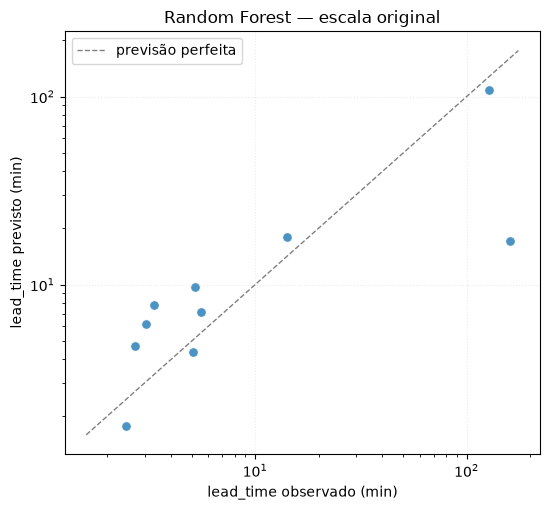

MAE na escala original: 18.41 min


In [25]:
previsto_min = pipe.inverse_transform_y(busca.best_estimator_.predict(X_test), "lead_time")
observado_min = test_df["lead_time_mean"].to_numpy(float)

fig, eixo = plt.subplots(figsize=(5.6, 5.2))
lim = [min(observado_min.min(), previsto_min.min()) * 0.9,
       max(observado_min.max(), previsto_min.max()) * 1.1]
eixo.plot(lim, lim, "--", color="gray", linewidth=1, label="previsão perfeita")
eixo.scatter(observado_min, previsto_min, s=45, alpha=0.8, edgecolor="white", linewidth=0.5)
eixo.set_xscale("log"); eixo.set_yscale("log")
eixo.set_xlabel("lead_time observado (min)")
eixo.set_ylabel("lead_time previsto (min)")
eixo.set_title("Random Forest — escala original")
eixo.legend(); eixo.grid(alpha=0.25, linestyle=":")
plt.tight_layout(); plt.show()

print(f"MAE na escala original: {np.mean(np.abs(previsto_min - observado_min)):.2f} min")

---
## Resumo

O percurso confirmou que a cadeia implementada faz o que precisa fazer:

| Etapa | Verificado |
|---|---|
| Espaço de parâmetros | Quatro naturezas de fator declaradas fora do código |
| Amostragem | Os três métodos são **distintos**; Monte Carlo funciona como *baseline* |
| Preenchimento do espaço | Sete métricas comparando os três métodos |
| Replicações | Uma linha por execução, sementes determinísticas, `dtypes` preservados |
| Resultado do DoE | `.describe()` e o *DataFrame* completo |
| Simulação (fingida) | KPIs assimétricos e heterocedásticos, como o SED real |
| Agregação | Média, desvio, $n$, erro padrão e peso por ponto |
| Teto de ruído | Calculado, com o limite do $R^2$ atingível |
| Pré-processamento | Entradas determinísticas, alvo sem vazamento, reversível |
| Metamodelo | Random Forest treinado, com peso convertido para a escala do alvo, busca de hiperparâmetros e volta à escala original |

**Fora deste notebook, por não estarem implementadas:** a avaliação estatística formal
(Fase 4) e a camada de explicabilidade (Fase 5).